In [ ]:
# QUIERO HACER UN CONTROLADOR FUZZY
## Primero inportamos las librerías



In [ ]:
pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 14.9 MB/s eta 0:00:00


In [ ]:
import skfuzzy as fuzz
print("scikit-fuzzy installed and imported successfully!")

scikit-fuzzy installed and imported successfully!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
print("numpy and matplotlib installed and imported successfully!")

numpy and matplotlib installed and imported successfully!


### 1. Universo del Discurso

Primero, define el rango de valores para tu variable (el universo del discurso). Por ejemplo, si tienes una variable de 'temperatura' que va de 0 a 100 grados.

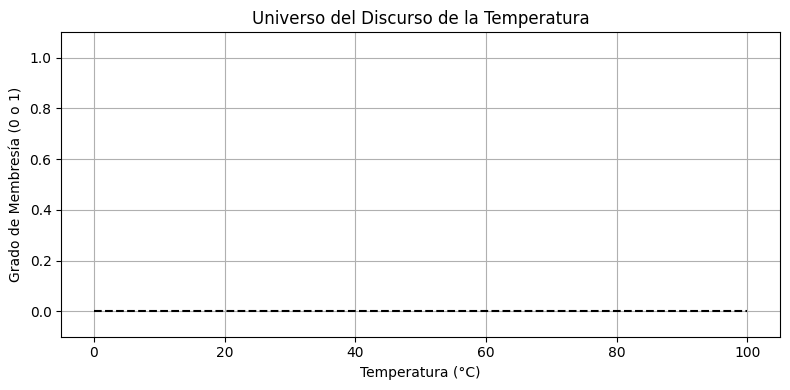

In [ ]:
# Generar el universo del discurso para una variable (e.g., Temperatura de 0 a 100)
x_temperatura = np.arange(0, 101, 1)

# Visualizar el universo del discurso (opcional)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x_temperatura, np.zeros_like(x_temperatura), 'k--') # Representa el eje x
ax.set_title('Universo del Discurso de la Temperatura')
ax.set_xlabel('Temperatura (°C)')
ax.set_ylabel('Grado de Membresía (0 o 1)')
ax.set_ylim(-0.1, 1.1) # Asegura que se vea bien
plt.grid(True)
plt.tight_layout()
plt.show()

### 2. Funciones de Membresía Triangular (`trimf`)

Una función triangular se define por tres puntos: el inicio, el pico y el final del triángulo.

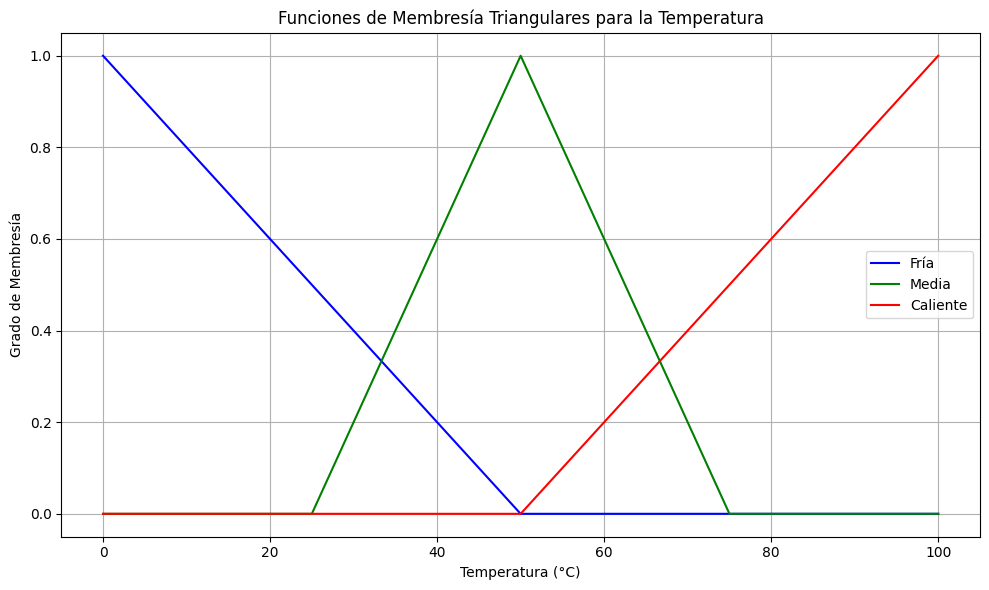

In [ ]:
# Definir funciones de membresía triangulares para la temperatura
temperatura_fria = fuzz.trimf(x_temperatura, [0, 0, 50])
temperatura_media = fuzz.trimf(x_temperatura, [25, 50, 75])
temperatura_caliente = fuzz.trimf(x_temperatura, [50, 100, 100])

# Visualizar las funciones de membresía
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_temperatura, temperatura_fria, 'b', linewidth=1.5, label='Fría')
ax.plot(x_temperatura, temperatura_media, 'g', linewidth=1.5, label='Media')
ax.plot(x_temperatura, temperatura_caliente, 'r', linewidth=1.5, label='Caliente')
ax.set_title('Funciones de Membresía Triangulares para la Temperatura')
ax.set_ylabel('Grado de Membresía')
ax.set_xlabel('Temperatura (°C)')
ax.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 3. Funciones de Membresía Trapezoidales (`trapmf`)

Una función trapezoidal se define por cuatro puntos: los dos puntos donde la membresía empieza a subir, y los dos puntos donde alcanza el valor máximo (1) y donde empieza a bajar.

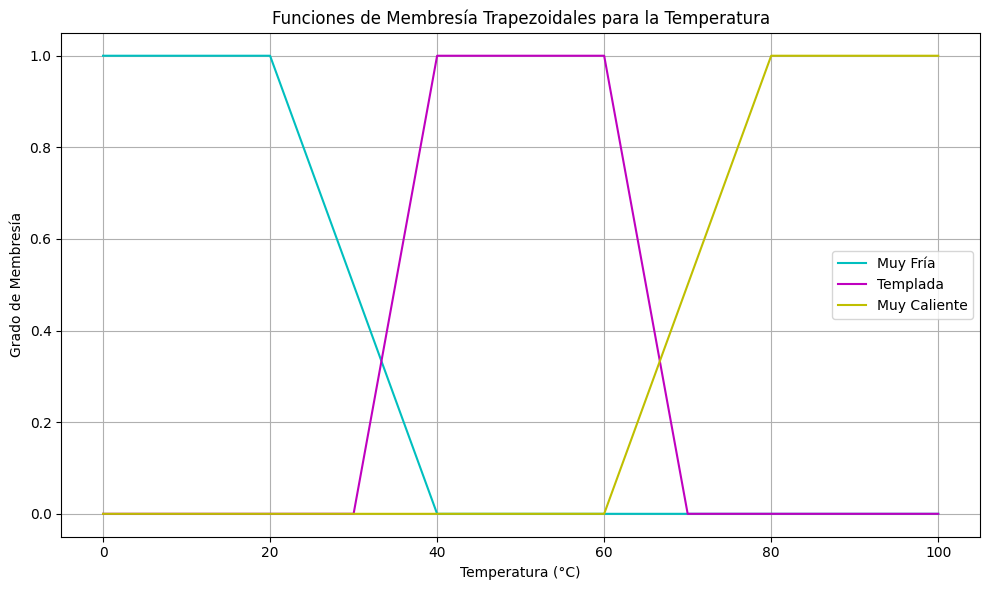

In [ ]:
# Definir funciones de membresía trapezoidales para la temperatura
temperatura_muy_fria = fuzz.trapmf(x_temperatura, [0, 0, 20, 40])
temperatura_templada = fuzz.trapmf(x_temperatura, [30, 40, 60, 70])
temperatura_muy_caliente = fuzz.trapmf(x_temperatura, [60, 80, 100, 100])

# Visualizar las funciones de membresía
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_temperatura, temperatura_muy_fria, 'c', linewidth=1.5, label='Muy Fría')
ax.plot(x_temperatura, temperatura_templada, 'm', linewidth=1.5, label='Templada')
ax.plot(x_temperatura, temperatura_muy_caliente, 'y', linewidth=1.5, label='Muy Caliente')
ax.set_title('Funciones de Membresía Trapezoidales para la Temperatura')
ax.set_ylabel('Grado de Membresía')
ax.set_xlabel('Temperatura (°C)')
ax.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 4. Funciones de Membresía Gaussianas (`gaussmf`)

Una función gaussiana se define por un centro y una desviación estándar. Es suave y continua, a menudo preferida en ciertas aplicaciones por su diferenciabilidad.

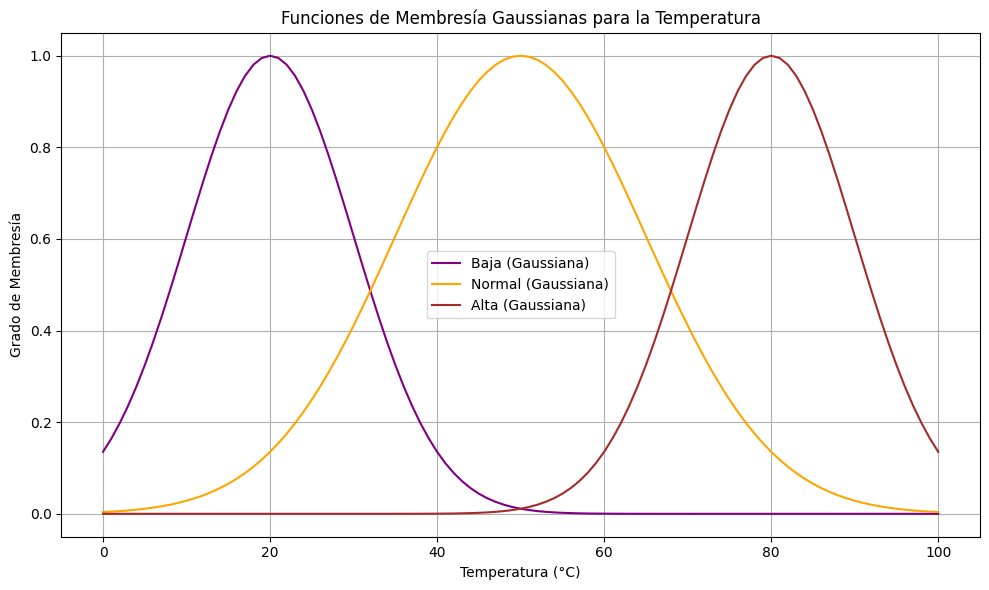

In [ ]:
# Definir funciones de membresía gaussianas para la temperatura
temperatura_baja_gauss = fuzz.gaussmf(x_temperatura, 20, 10) # centro 20, sigma 10
temperatura_normal_gauss = fuzz.gaussmf(x_temperatura, 50, 15) # centro 50, sigma 15
temperatura_alta_gauss = fuzz.gaussmf(x_temperatura, 80, 10) # centro 80, sigma 10

# Visualizar las funciones de membresía
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_temperatura, temperatura_baja_gauss, 'purple', linewidth=1.5, label='Baja (Gaussiana)')
ax.plot(x_temperatura, temperatura_normal_gauss, 'orange', linewidth=1.5, label='Normal (Gaussiana)')
ax.plot(x_temperatura, temperatura_alta_gauss, 'brown', linewidth=1.5, label='Alta (Gaussiana)')
ax.set_title('Funciones de Membresía Gaussianas para la Temperatura')
ax.set_ylabel('Grado de Membresía')
ax.set_xlabel('Temperatura (°C)')
ax.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### 5. Funciones de Membresía Gaussianas para la Potencia del Ventilador

Definiremos un universo del discurso de 0 a 5V para la potencia del ventilador y crearemos funciones de membresía gaussianas para representar los niveles de potencia deseados (0%, 25%, 50%, 75% y 100%).

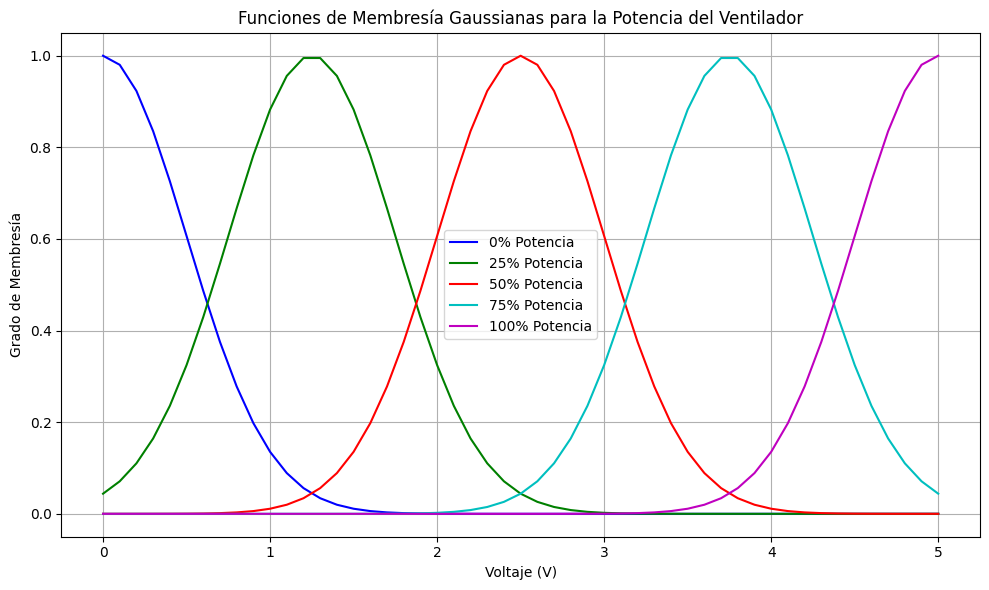

In [ ]:
# 1. Universo del Discurso para la Potencia del Ventilador (0 a 5V)
x_power = np.arange(0, 5.1, 0.1) # De 0 a 5 voltios, con incrementos de 0.1V

# 2. Definir funciones de membresía gaussianas para los niveles de potencia
# Se eligen centros correspondientes a los porcentajes de potencia y un sigma (desviación estándar) para la 'difusidad'
power_0_percent = fuzz.gaussmf(x_power, 0, 0.5)   # Centro en 0V, sigma 0.5
power_25_percent = fuzz.gaussmf(x_power, 1.25, 0.5) # Centro en 1.25V (25% de 5V), sigma 0.5
power_50_percent = fuzz.gaussmf(x_power, 2.5, 0.5)  # Centro en 2.5V (50% de 5V), sigma 0.5
power_75_percent = fuzz.gaussmf(x_power, 3.75, 0.5) # Centro en 3.75V (75% de 5V), sigma 0.5
power_100_percent = fuzz.gaussmf(x_power, 5, 0.5)  # Centro en 5V (100% de 5V), sigma 0.5

# 3. Visualizar las funciones de membresía
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_power, power_0_percent, 'b', linewidth=1.5, label='0% Potencia')
ax.plot(x_power, power_25_percent, 'g', linewidth=1.5, label='25% Potencia')
ax.plot(x_power, power_50_percent, 'r', linewidth=1.5, label='50% Potencia')
ax.plot(x_power, power_75_percent, 'c', linewidth=1.5, label='75% Potencia')
ax.plot(x_power, power_100_percent, 'm', linewidth=1.5, label='100% Potencia')

ax.set_title('Funciones de Membresía Gaussianas para la Potencia del Ventilador')
ax.set_ylabel('Grado de Membresía')
ax.set_xlabel('Voltaje (V)')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

### 6. Grado de Membresía para una Entrada de Temperatura Específica

Primero, calcularemos el grado de membresía para una temperatura de 20 grados en las funciones de membresía gaussianas que definimos anteriormente para la temperatura (baja, normal, alta).

In [ ]:
# Calcular el grado de membresía para una temperatura de 20 grados
temp_input = 20

temp_baja_mf = fuzz.interp_membership(x_temperatura, temperatura_baja_gauss, temp_input)
temp_normal_mf = fuzz.interp_membership(x_temperatura, temperatura_normal_gauss, temp_input)
temp_alta_mf = fuzz.interp_membership(x_temperatura, temperatura_alta_gauss, temp_input)

print(f"Para una temperatura de {temp_input}°C:")
print(f"  Grado de membresía en 'Temperatura Baja (Gaussiana)': {temp_baja_mf:.3f}")
print(f"  Grado de membresía en 'Temperatura Normal (Gaussiana)': {temp_normal_mf:.3f}")
print(f"  Grado de membresía en 'Temperatura Alta (Gaussiana)': {temp_alta_mf:.3f}")

Para una temperatura de 20°C:
  Grado de membresía en 'Temperatura Baja (Gaussiana)': 1.000
  Grado de membresía en 'Temperatura Normal (Gaussiana)': 0.135
  Grado de membresía en 'Temperatura Alta (Gaussiana)': 0.000


### 7. Conexión de Entrada a Salida: Definición de Reglas Difusas

Para obtener un valor de membresía del voltaje del ventilador (salida) a partir de esta temperatura de entrada, necesitamos definir *reglas difusas*. Estas reglas establecen cómo las diferentes condiciones de entrada (como 'Temperatura Baja') influyen en las diferentes condiciones de salida (como 'Potencia Baja').

**Ejemplos de reglas:**
*   **SI** la `Temperatura` es **BAJA**, **ENTONCES** la `Potencia del Ventilador` es **ALTA**.
*   **SI** la `Temperatura` es **NORMAL**, **ENTONCES** la `Potencia del Ventilador` es **MEDIA**.
*   **SI** la `Temperatura` es **ALTA**, **ENTONCES** la `Potencia del Ventilador` es **BAJA**.

Una vez que definamos estas reglas, podemos usar un sistema de inferencia difuso (como el que proporciona `skfuzzy.control`) para calcular la salida difusa y, finalmente, desdifuminarla a un valor nítido (un voltaje específico) si es necesario.

¿Quieres que te ayude a definir estas reglas y a configurar el sistema de control difuso?

### 8. Definición del Sistema de Control Difuso y Reglas

Primero, definimos las variables de entrada y salida para el sistema de control difuso, asociando los universos del discurso y las funciones de membresía que ya creamos.

In [ ]:
from skfuzzy import control as ctrl

# Nueva instancia de Input/Output
temperatura = ctrl.Antecedent(x_temperatura, 'temperatura')
potencia_ventilador = ctrl.Consequent(x_power, 'potencia_ventilador')

# Asignar las funciones de membresía definidas previamente a las variables
temperatura['baja'] = temperatura_baja_gauss
temperatura['normal'] = temperatura_normal_gauss
temperatura['alta'] = temperatura_alta_gauss

potencia_ventilador['cero'] = power_0_percent
potencia_ventilador['baja'] = power_25_percent # Mapeamos 'baja' a 25% por los ejemplos
potencia_ventilador['media'] = power_50_percent
potencia_ventilador['alta'] = power_100_percent # Mapeamos 'alta' a 100% por los ejemplos

# Visualizar las variables con sus funciones de membresía (opcional)
# temperatura.view()
# potencia_ventilador.view()


Ahora, definimos las reglas difusas basándonos en los ejemplos proporcionados:

*   **SI** la `Temperatura` es **BAJA**, **ENTONCES** la `Potencia del Ventilador` es **BAJA**.
*   **SI** la `Temperatura` es **NORMAL**, **ENTONCES** la `Potencia del Ventilador` es **MEDIA**.
*   **SI** la `Temperatura` es **ALTA**, **ENTONCES** la `Potencia del Ventilador` es **ALTA**.

In [ ]:
# Definir las reglas difusas
rule1 = ctrl.Rule(temperatura['baja'], potencia_ventilador['baja'])
rule2 = ctrl.Rule(temperatura['normal'], potencia_ventilador['media'])
rule3 = ctrl.Rule(temperatura['alta'], potencia_ventilador['alta'])

# Crear el sistema de control
control_sistema_ventilador = ctrl.ControlSystem([rule1, rule2, rule3])

# Crear la simulación del sistema de control
simulacion_ventilador = ctrl.ControlSystemSimulation(control_sistema_ventilador)

print("Sistema de control difuso y reglas definidos.")

Sistema de control difuso y reglas definidos.


### 9. Ejemplo de Inferencia y Desdifusión

Usaremos el ejemplo de una temperatura de entrada de 20 grados para ver cómo el sistema infiere la potencia del ventilador y desdifusa el resultado.

Para una temperatura de entrada de 20°C:
  La potencia del ventilador calculada (desdifusa) es: 1.48 V


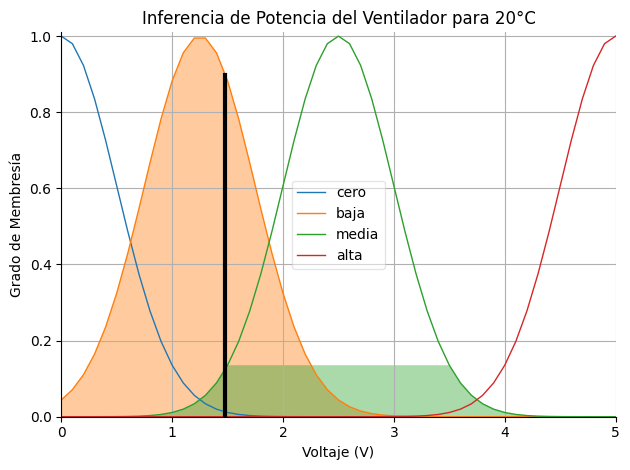

In [ ]:
# Establecer un valor de entrada para la temperatura
input_temperatura_ejemplo = 20
simulacion_ventilador.input['temperatura'] = input_temperatura_ejemplo

# Computar la inferencia difusa
simulacion_ventilador.compute()

# Obtener el resultado desdifuso (la potencia del ventilador en Voltios)
salida_potencia_ventilador = simulacion_ventilador.output['potencia_ventilador']

print(f"Para una temperatura de entrada de {input_temperatura_ejemplo}°C:")
print(f"  La potencia del ventilador calculada (desdifusa) es: {salida_potencia_ventilador:.2f} V")

# Visualizar la inferencia
potencia_ventilador.view(sim=simulacion_ventilador)
plt.title(f'Inferencia de Potencia del Ventilador para {input_temperatura_ejemplo}°C')
plt.xlabel('Voltaje (V)')
plt.ylabel('Grado de Membresía')
plt.grid(True)
plt.tight_layout()
plt.show()